In [1]:
# Project Title: Social Media Engagement Analytics Using Python
# Assignment Tasks:
# ❖ Task 1 — Data Import & Setup
# ○ Import CSV using Pandas
# ○ Check/convert data types
# ○ Convert date columns to datetime

# Load the CSV dataset                                                           # Used AI Support

from google.colab import files

uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [2]:
import os
print(os.listdir())

['.config', 'social_media_engagement_5000.csv', 'sample_data']


In [3]:
import pandas as pd
import numpy as np
df = pd.read_csv("social_media_engagement_5000.csv")

print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [4]:
# View dataset structure

print("\nDataset Information:")
print(df.info())

# Check data types

print("\nData Types:")
print(df.dtypes)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         48

In [5]:
# Example: Convert numeric columns if they are stored as object

numeric_cols = ['Likes', 'Comments', 'Shares', 'Impressions', 'Watch_Time']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')                        # coerce is commonly used with pd.to_numeric() and pd.to_datetime().

print("\nUpdated Data Types:")
print(df.dtypes)


Updated Data Types:
user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [6]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


In [7]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

# Verify conversion

print(df['posted_at'].dtype)


datetime64[ns]


/tmp/ipykernel_2617/312735920.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'])


In [8]:
# Task 2 — Data Cleaning
# ●  Cleaning Missing Data
# ■ Detect missing values (isnull(), isna())
# ■ Handle using: dropna(), fillna(), median/mode, forward/backward-fill

# Check missing values in each column

print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [9]:
df_drop = df.dropna()

print("Original Shape:", df.shape)
print("After dropna():", df_drop.shape)

Original Shape: (5000, 19)
After dropna(): (4162, 19)


In [10]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

In [11]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [12]:
df.ffill(inplace=True)                                                           # ffill takes the previous valid value and fills the missing value.
df.bfill(inplace=True)                                                           # bfill takes the next valid value and fills the missing value.

In [13]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [14]:
# Identify duplicates

print(df.duplicated().sum())

# Remove duplicates

df.drop_duplicates(inplace=True)

# Verify

print(df.duplicated().sum())

0
0


In [15]:
# Data Formatting
# ■ Fix incorrect data types
# ■ Standardize categories (e.g., gender labels)
# ■ Correct unrealistic values in likes, comments, shares

# Standardize gender labels

df['gender'] = df['gender'].replace({                                            # replace() is a Pandas function used to find specific values and substitute them with new values.
    'male': 'Male',
    'M': 'Male',
    'female': 'Female',
    'F': 'Female'
})

# Correct unrealistic values                                                     # In your dataset: Likes cannot be negative,
                                                                                 # Comments cannot be negative, Shares cannot be negative.
df.loc[df['likes'] < 0, 'likes'] = df['likes'].median()
df.loc[df['comments'] < 0, 'comments'] = df['comments'].median()
df.loc[df['shares'] < 0, 'shares'] = df['shares'].median()


In [16]:
# Feature Cleaning
# ■ Extract hashtag count
# ■ Clean sentiment labels

# Extract hashtag count

df['hashtag_count'] = df['hashtags'].fillna('').apply(                           # Selects the hashtags column.Replaces missing values (NaN) with an empty string ('').
    lambda x: len(str(x).split(',')) if x != '' else 0                           # This prevents errors when counting hashtags.
)                                                                                # x represents each row value.
                                                                                 # The lambda function tells Pandas what operation to perform on each value.
# Clean sentiment labels

df['sentiment'] = df['sentiment'].str.strip().str.title()                        # Removes leading and trailing spaces.

# Verify

print(df[['hashtags', 'hashtag_count']].head())                                  # Shows all unique sentiment values in the column.
print(df['sentiment'].unique())                                                  # Shows all unique sentiment values in the column.

                hashtags  hashtag_count
0  #foodie #travel #love              1
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              1
4                #travel              1
['Negative' 'Positive' 'Neutral']


In [17]:
# Task 3 — Data Exploration using Pandas Perform the following:
# ● View dataset structure using head(), tail(), shape, and columns.
# ● Check data types and info with info() and dtypes.
# ● Generate summary statistics using describe().
# ● Analyze categorical distributions using value_counts(), unique(), and nunique().
# ● Create a correlation matrix for numeric fields.
# ● Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).

print(df.head())
print(df.tail())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [18]:
print("Rows and Columns:", df.shape)
print(df.columns)

Rows and Columns: (5000, 20)
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')


In [19]:
df.info()
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [20]:
print(df.describe())                                          # summary statistics for all numerical columns in the DataFrame.
print(df.describe(include='all'))                             # Shows summary statistics for all columns, including: Numerical, String(Objects) & Categorical Columns.

            user_id          age        post_id         likes     comments  \
count   5000.000000  5000.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.440400  548042.909000  10106.997400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.687151  260646.957267   5702.293017   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000     4034.5

In [21]:
print(df['gender'].value_counts())                          # value_counts() is a Pandas function used to count how many times each unique value appears in a column.
print(df['country'].value_counts())
print(df['sentiment'].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [22]:
print(df['post_type'].unique())                                                  # Returns all distinct (unique) values present in a column. w/o Duplicates.
print(df['sentiment'].unique())
print(df['country'].nunique())
print(df['post_type'].nunique())                                                 # Returns the count of unique values.
print(df['hashtags'].nunique())

['image' 'reel' 'text' 'video']
['Negative' 'Positive' 'Neutral']
10
4
761


In [23]:
# Create a correlation matrix for numeric fields.

corr_matrix = df.corr(numeric_only=True)                                         # Correlation measures the relationship between two numerical columns.
                                                                                 # Calculates correlation between all numerical columns.
print(corr_matrix)                                                               # Use only numeric columns and ignore text columns.

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
is_verified       0.004058 -0.000079  0.025208 -0.016200 -0.012398  0.007025   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count          NaN       NaN    

In [24]:
# Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).

avg_likes = df.groupby('post_type')['likes'].mean()                              # Group rows based on a column and then perform calculations on each group.
print(avg_likes)

avg_comments = df.groupby('post_type')['comments'].mean()                        # On average, Video posts receive more likes than Image posts.
print(avg_comments)
                                                                                 # Video posts get more comments on average. USA generated the highest total impressions.
country_impressions = df.groupby('country')['impression_count'].sum()
print(country_impressions)

sentiment_engagement = df.groupby('sentiment')['engagement_rate'].mean()         # Positive posts have better engagement than Negative posts.
print(sentiment_engagement)

device_watchtime = df.groupby('device_type')['watch_time_sec'].mean()            # Desktop users watch content longer than Mobile users.
print(device_watchtime)

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64
post_type
image    1525.235766
reel     1504.187062
text     1499.106024
video    1479.160000
Name: comments, dtype: float64
country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64
sentiment
Negative    1.038486
Neutral     0.991170
Positive    0.919744
Name: engagement_rate, dtype: float64
device_type
desktop    3974.792521
mobile     4087.830760
tablet     3979.736429
Name: watch_time_sec, dtype: float64


In [25]:
# Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).

summary = df.groupby('post_type').agg({                            # powerful version of groupby() because of calculating multiple summaries at once using agg().
    'likes':'mean',
    'comments':'mean',
    'shares':'mean',
    'engagement_rate':'mean'
})

print(summary)

                  likes     comments       shares  engagement_rate
post_type                                                         
image      10104.865277  1525.235766  1019.289495         0.895646
reel       10037.802416  1504.187062   982.042089         0.783047
text       10100.148193  1499.106024  1013.989558         1.064549
video      10188.600000  1479.160000   996.834286         1.122365


In [26]:
# Task 4 — Data Wrangling
# ● Use merge, concat, or join if combining DataFrames.
# ● Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag count.
# ● Perform groupby summaries by post_type, country, and sentiment.

import numpy as np                                                               # NumPy provides mathematical functions and numerical operations.

# Engagement Score

df['engagement_score'] = (
    df['likes']
    + 2 * df['comments']
    + 3 * df['shares']
)

# Log Transform

df['log_likes'] = np.log1p(df['likes'])                                 # Without NumPy, the log function is not directly available.

# Hashtag Count

df['hashtag_count'] = df['hashtags'].fillna('').str.count('#')          # fillna() -> replaces missing values with an empty string.
                                                                        # str.count('#') counts the number of hashtag symbols in each post and creates a new feature called hashtag_count.
# Post Type Summary

post_summary = df.groupby('post_type').agg({                            # agg() (aggregation) is used to apply summary functions such as mean, sum, min, max, and count on multiple columns simultaneously.
    'likes':'mean',
    'comments':'mean',
    'shares':'mean',
    'engagement_score':'mean'
})

# Country Summary

country_summary = df.groupby('country').agg({
    'impression_count':'sum',
    'engagement_rate':'mean'
})

# Sentiment Summary

sentiment_summary = df.groupby('sentiment').agg({
    'likes':'mean',
    'comments':'mean',
    'shares':'mean'
})

print(post_summary)
print(country_summary)
print(sentiment_summary)

                  likes     comments       shares  engagement_score
post_type                                                          
image      10104.865277  1525.235766  1019.289495      16213.205293
reel       10037.802416  1504.187062   982.042089      15992.302806
text       10100.148193  1499.106024  1013.989558      16140.328916
video      10188.600000  1479.160000   996.834286      16137.422857
           impression_count  engagement_rate
country                                     
Australia          23834767         1.324339
Brazil             24793360         1.540704
Canada             24984716         0.916659
France             25656926         1.146402
Germany            23816649         0.759000
India              28067377         0.655005
Japan              23418816         0.769623
UAE                24610992         1.112352
UK                 25201861         0.850966
USA                25683200         0.576580
                  likes     comments       shares
se

In [27]:
# Task 5 — Statistical Analysis  Compute descriptive stats for “likes, comments, shares, watch_time, engagement_rate, followers” columns:
# ● Mean, median, mode
# ● Standard deviation, variance
# ● Percentiles
# ● (Optional) Skewness and kurtosis

cols = ['likes', 'comments', 'shares',
        'watch_time_sec', 'engagement_rate',
        'follower_count']

print("Mean")
print(df[cols].mean())                                                           # Mean represents the average value of a column.

print("\nMedian")
print(df[cols].median())                                                         # Median gives the middle value after sorting.

print("\nMode")
print(df[cols].mode().iloc[0])                                                   # Mode identifies the most frequently occurring value.

print("\nStandard Deviation")
print(df[cols].std())                                                            # Measures how spread out the data is around the mean.

print("\nVariance")
print(df[cols].var())                                                            # Variance measures data dispersion and is the square of the standard deviation.

print("\nPercentiles")
print(df[cols].quantile([0.25, 0.50, 0.75]))                 # Percentiles help understand data distribution by showing the values below which a certain percentage of observations fall.

print("\nSkewness")
print(df[cols].skew())                                       # Skewness measures the asymmetry of a distribution. Positive skew indicates a right tail and negative skew indicates a left tail.

print("\nKurtosis")
print(df[cols].kurt())                                       # Kurtosis measures the presence of extreme values or outliers in a distribution.


Mean
likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

Median
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

Mode
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

Standard Deviation
likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

Variance
likes              3.251615e+07
comments           7.334095e+05
shares             3.25875

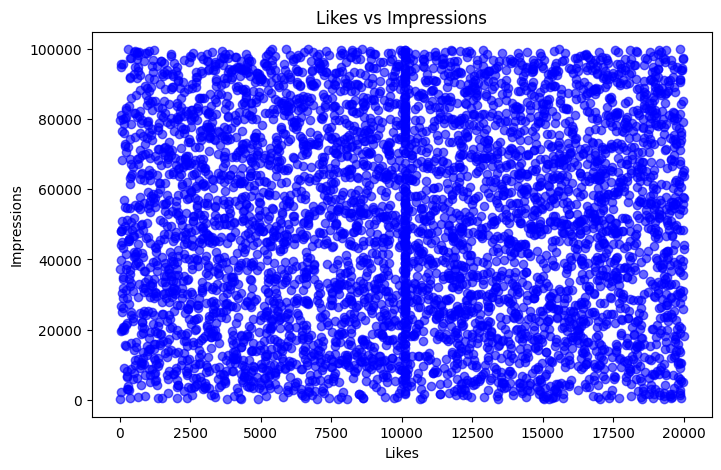

In [28]:
# ❖ Task 6 — Data Visualization (Min. 8 Plots Required)
# ● Matplotlib
# ○ Scatter: likes vs impressions
# ○ Line: daily engagement trend
# ○ Bar: posts by category
# ○ Pie: gender distribution
# ○ Histogram: age
# ○ Box: engagement rate

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(df['likes'], df['impression_count'], color='blue', alpha=0.6)

plt.title('Likes vs Impressions')
plt.xlabel('Likes')
plt.ylabel('Impressions')
plt.show()

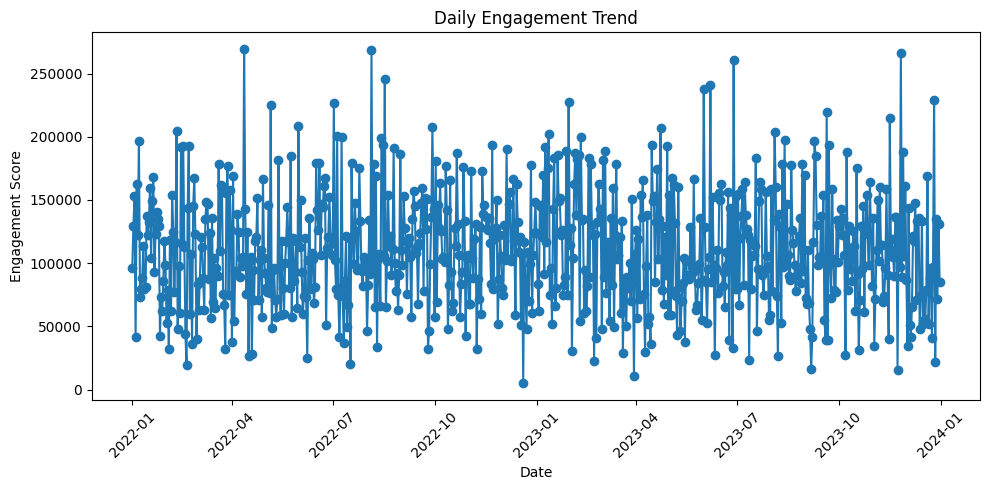

In [29]:
# ○ Line: daily engagement trend
import pandas as pd

df['posted_at'] = pd.to_datetime(df['posted_at'])

daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_score'].sum()

plt.figure(figsize=(10,5))
plt.plot(daily_engagement.index,
         daily_engagement.values,
         marker='o')

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Engagement Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

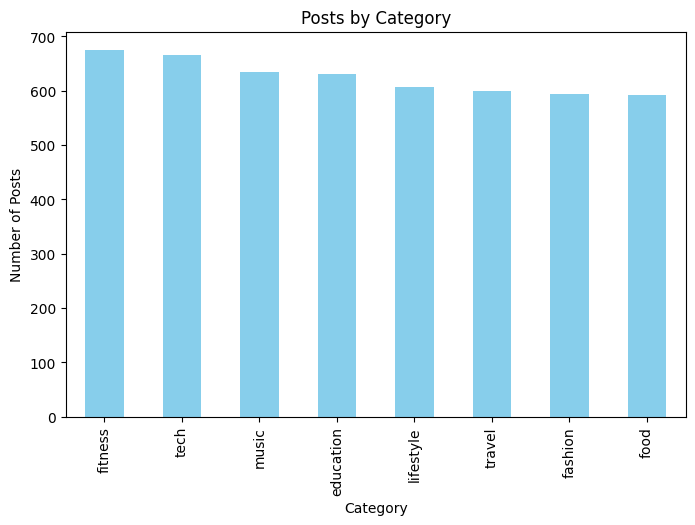

In [30]:
# Bar: posts by category
df['post_category'].value_counts().plot(
    kind='bar',
    figsize=(8,5),
    color='skyblue'
)

plt.title('Posts by Category')
plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.show()

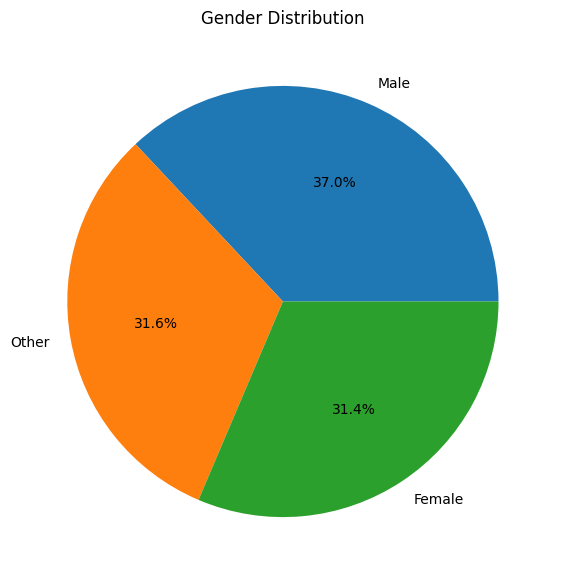

In [31]:
#  Pie: gender distribution
gender_count = df['gender'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')
plt.show()

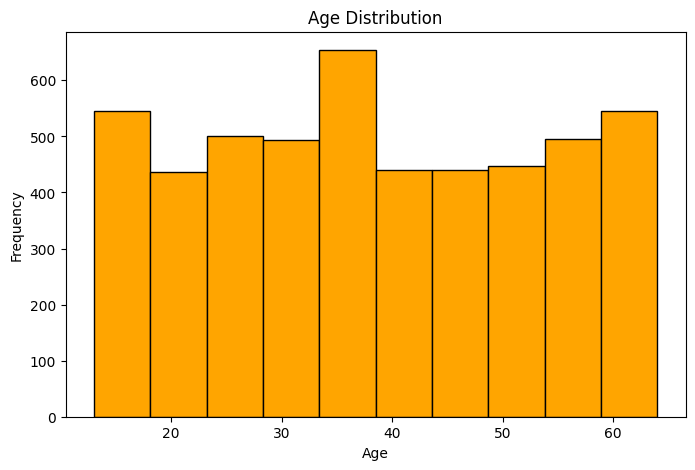

In [32]:
# Histogram: age
plt.figure(figsize=(8,5))

plt.hist(
    df['age'],
    bins=10,
    color='orange',
    edgecolor='black'
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

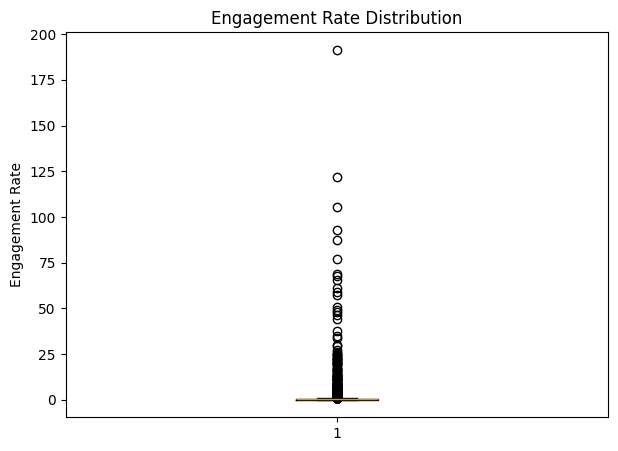

In [33]:
# Box: engagement rate
plt.figure(figsize=(7,5))

plt.boxplot(df['engagement_rate'])

plt.title('Engagement Rate Distribution')
plt.ylabel('Engagement Rate')
plt.show()

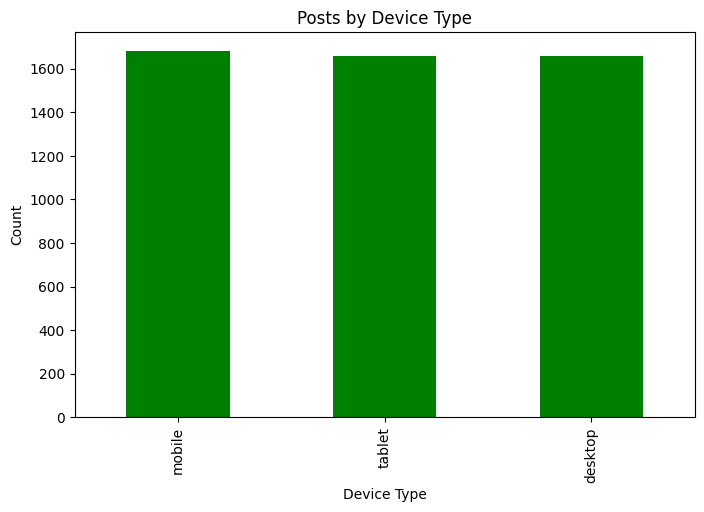

In [34]:
# 7. Bar Chart: Device Type Distribution

df['device_type'].value_counts().plot(
    kind='bar',
    color='green',
    figsize=(8,5)
)

plt.title('Posts by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Count')
plt.show()

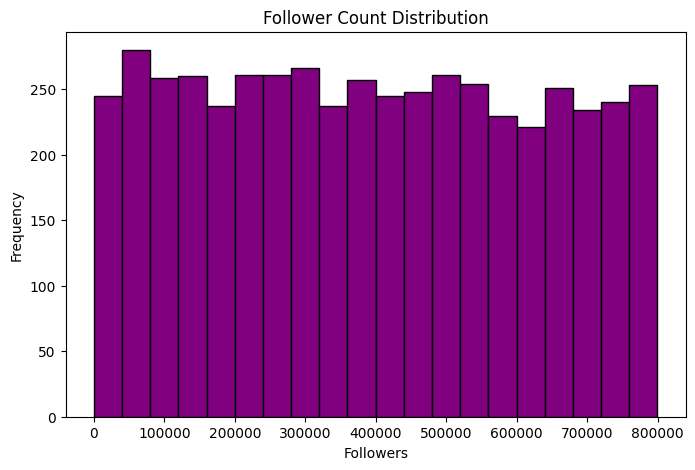

In [35]:
# 8. Histogram: Follower Count

plt.figure(figsize=(8,5))

plt.hist(
    df['follower_count'],
    bins=20,
    color='purple',
    edgecolor='black'
)

plt.title('Follower Count Distribution')
plt.xlabel('Followers')
plt.ylabel('Frequency')
plt.show()



In [36]:
# Seaborn
# ○ Count plot: post type
# ○ Bar plot: avg likes by category
# ○ Violin: followers vs sentiment
# ○ Pair plot: numeric features
# ○ Heatmap: correlation matrix
# ○ Swarm plot: engagement vs device

/tmp/ipykernel_2617/4187245344.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='post_type', palette='Set2')


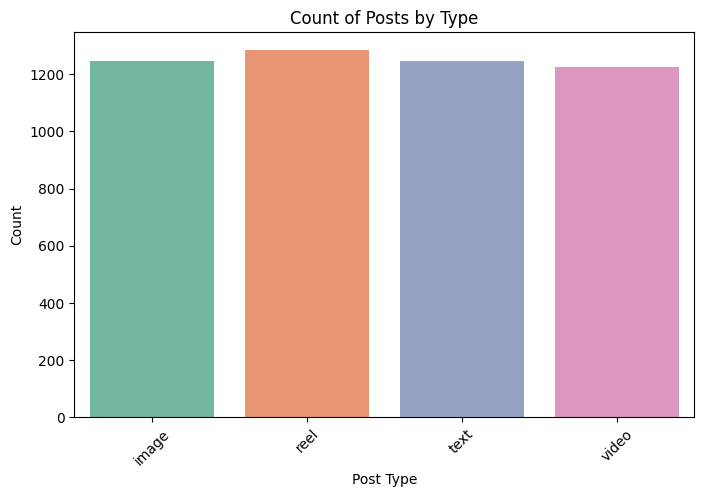

In [37]:
# Count Plot - Post Type

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='post_type', palette='Set2')

plt.title('Count of Posts by Type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_2617/1731813590.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


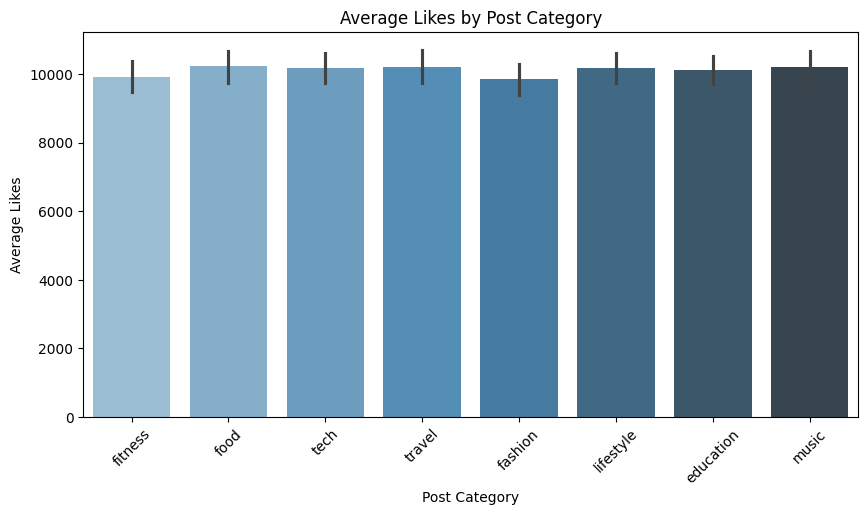

In [38]:
# Bar plot: avg likes by category

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    palette='Blues_d'
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)

plt.show()

/tmp/ipykernel_2617/3059685743.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


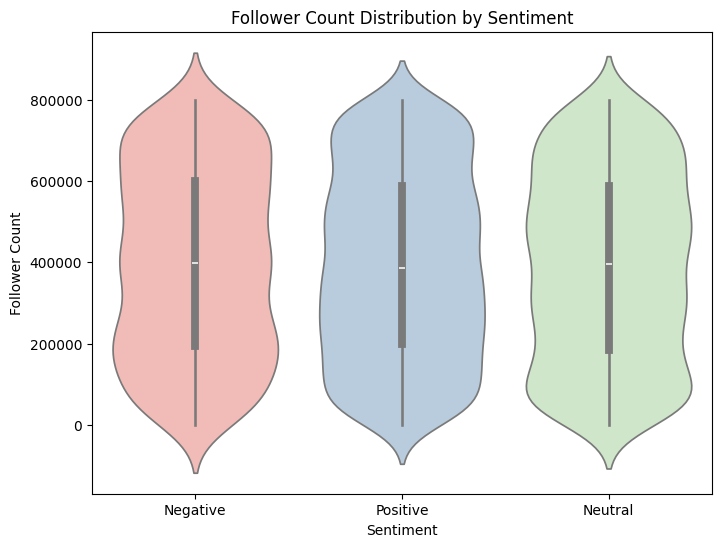

In [39]:
# Violin: followers vs sentiment
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count',
    palette='Pastel1'
)

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()


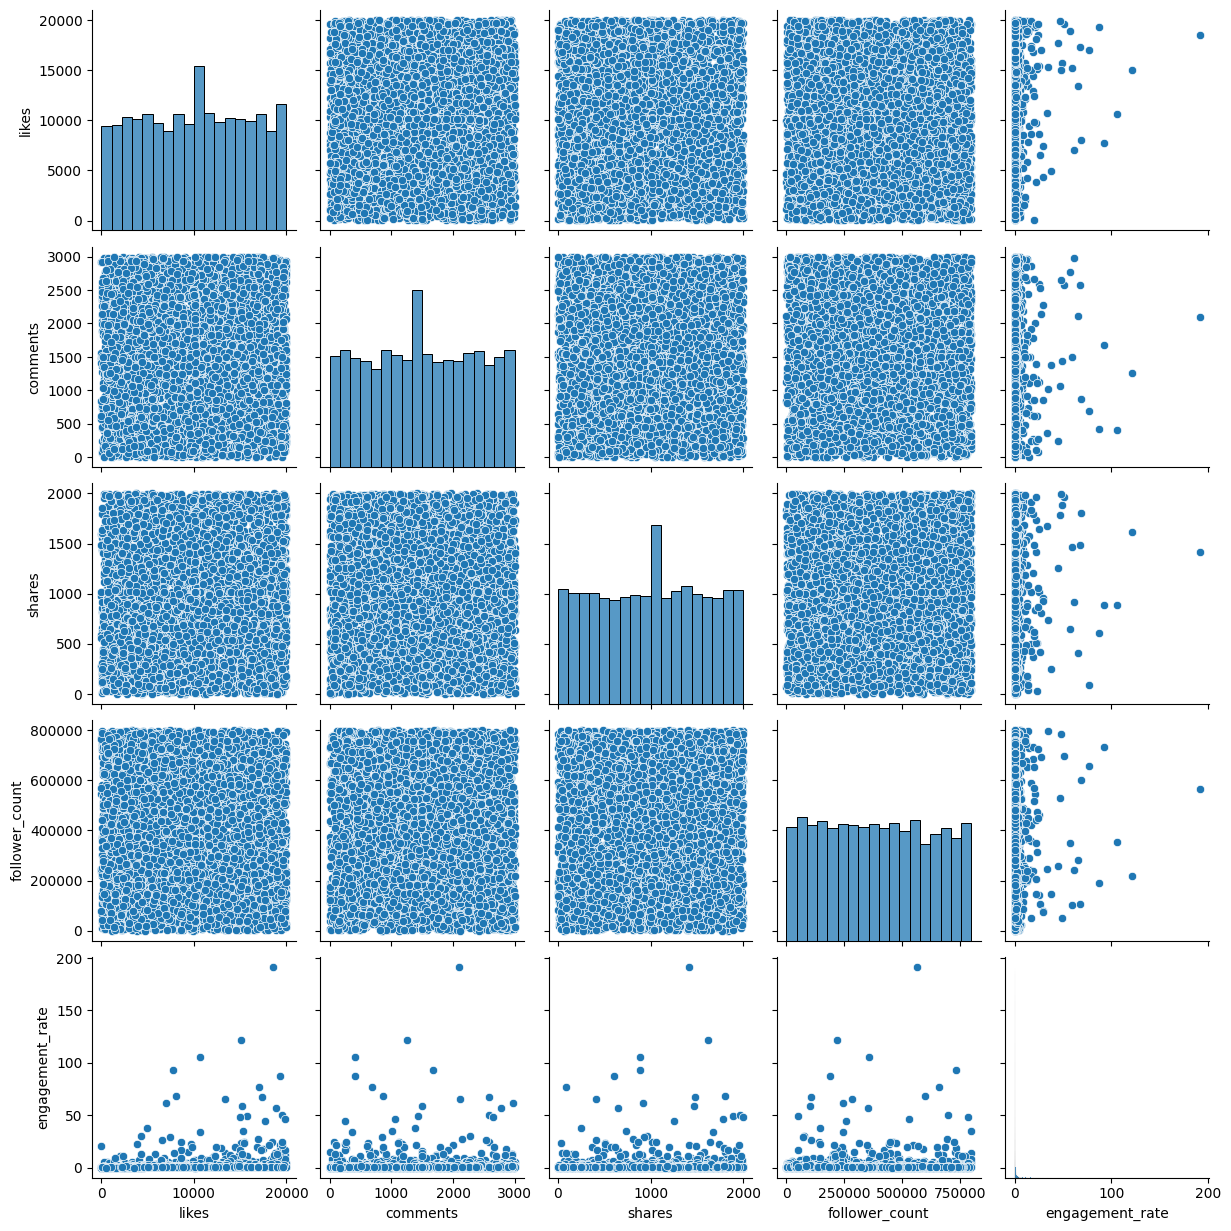

In [40]:
# Pair plot: numeric features
import seaborn as sns
import matplotlib.pyplot as plt

pair_data = df[
    ['likes',
     'comments',
     'shares',
     'follower_count',
     'engagement_rate']
].dropna()

sns.pairplot(pair_data)

plt.show()

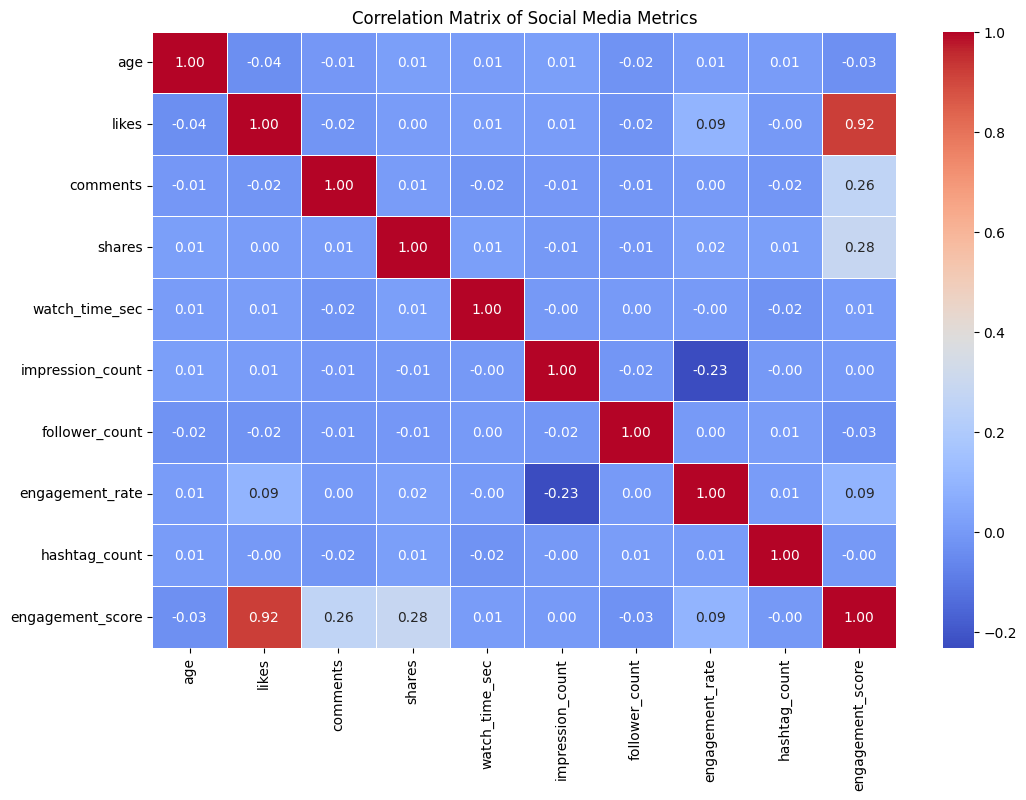

In [42]:
# Heatmap: correlation matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
corr_cols = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate',
    'hashtag_count',
    'engagement_score'
]

# Calculate correlation matrix
corr_matrix = df[corr_cols].corr()

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Social Media Metrics')
plt.show()

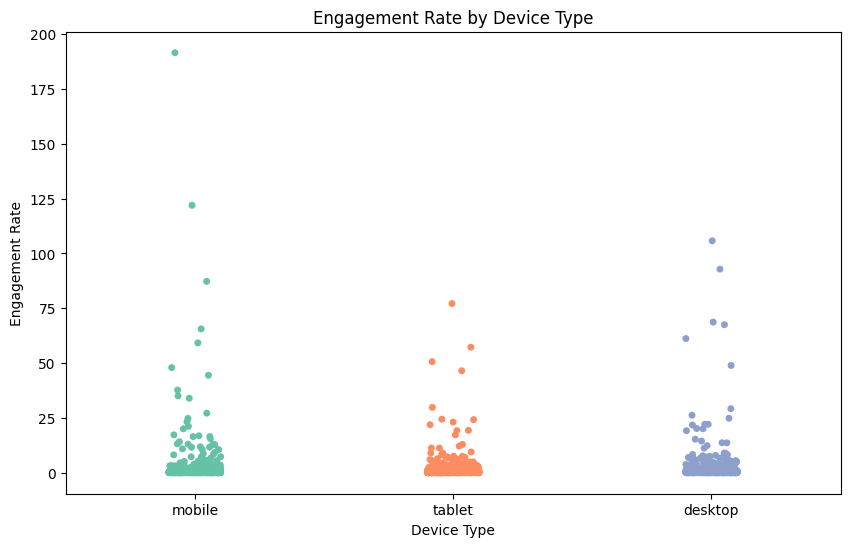

In [44]:
# Data analysts often use strip plots instead of swarm plots when the dataset is large because the visualization remains readable.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.stripplot(
    data=df,
    x='device_type',
    y='engagement_rate',
    hue='device_type',
    palette='Set2',
    jitter=True,
    legend=False
)

plt.title('Engagement Rate by Device Type')                                      # Used AI Support
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.show()

In [45]:
#Plotly (Interactive)
# Interactive line chart/bar chart/bubble/scatter chart
import pandas as pd
import plotly.express as px
#1. Interactive line chart — Daily engagement
print(df.columns)
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst="True")
df["engagement"]=df["likes"]+df["comments"]+df["shares"]
daily=df.groupby("posted_at")["engagement"].sum().reset_index()
fig=px.line(daily,x="posted_at",y="engagement",title="daily engagement trend")
fig.show()

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes'],
      dtype='object')


In [46]:
#Interactive bar chart — Average likes by category
avg_likes = df.groupby("post_category")["likes"].mean().reset_index()

fig=px.bar(avg_likes,x="post_category",y="likes",title="Average likes by category",color="post_category",barmode="group")

fig.show()

In [47]:
# Interactive bubble chart — Likes vs comments
fig=px.scatter(df,x="likes",y="comments",size="shares",color="post_category",hover_data="country")
fig.show()

In [48]:
#. Interactive scatter chart — Likes vs impressions
fig=px.scatter(df,x="impression_count",y="likes",color="device_type",title="likes and impressions")
fig.show()

In [49]:
#Content Performance
# Which post types have the highest engagement?
print(" Which post types have the highest engagement?")

print(df.groupby("post_type")["engagement"].mean().sort_values(ascending=False))

# Best-performing content category
print("Best-performing content category  :")
print(df.groupby("post_category")["engagement"].mean().sort_values(ascending=False))

# Countries with highest average engagement rate
print("Countries with highest average engagement rate   :")
print(df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False))

 Which post types have the highest engagement?
post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement, dtype: float64
Best-performing content category  :
post_category
music        12788.549606
food         12739.200675
tech         12686.490226
travel       12650.559167
lifestyle    12639.539539
education    12578.270206
fitness      12457.791852
fashion      12356.420875
Name: engagement, dtype: float64
Countries with highest average engagement rate   :
country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [50]:
#User Trends
# Engagement by age group
df["age_group"] = pd.cut(
    df["age"], bins=[0, 20, 30, 40, 50, 100],
    labels=["Below 20", "21-30", "31-40", "41-50", "Above 50"]
)
print("How age group affects the engagement   :")
print(df.groupby("age_group", observed=True)["engagement"].mean())

# Verified vs unverified accounts
print("Performance difference for verified accounts   :")
print(df.groupby("is_verified")["engagement"].mean())

How age group affects the engagement   :
age_group
Below 20    12854.529820
21-30       12622.617737
31-40       12938.497736
41-50       12658.455732
Above 50    12164.991622
Name: engagement, dtype: float64
Performance difference for verified accounts   :
is_verified
False    12644.311822
True     12309.280538
Name: engagement, dtype: float64


In [51]:
#Behavioral Insights
df["posted_at"] = pd.to_datetime(df["posted_at"], dayfirst=True)
df["hour"] = df["posted_at"].dt.hour
print("Best time of day for impressions   :")
print(df.groupby("hour")["impression_count"].mean().sort_values(ascending=False))
print("Device type impact on watch time    :")
print(df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False))

Best time of day for impressions   :
hour
0    50013.7328
Name: impression_count, dtype: float64
Device type impact on watch time    :
device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


In [52]:
#Which sentiment performs best?
print("Which sentiment performs best?")
print(df.groupby("sentiment")["engagement"].mean().sort_values(ascending=False))

# Negative and neutral post behavior
print("Behavior of negative/neutral sentiment posts   :")
print(
    df[df["sentiment"].isin(["negative", "neutral"])]
    .groupby("sentiment")[["likes", "comments", "shares", "engagement_rate"]]
    .mean()
)

Which sentiment performs best?
sentiment
Negative    12731.498958
Positive    12665.799443
Neutral     12448.163720
Name: engagement, dtype: float64
Behavior of negative/neutral sentiment posts   :
Empty DataFrame
Columns: [likes, comments, shares, engagement_rate]
Index: []
